# Gallbladder Disease Classification — Full Pipeline 

## Step 0 — Get the dataset onto this Colab

1. Open **https://data.mendeley.com/datasets/r6h24d2d3y/2** and click **"Download All"**.
2. Upload the zip to Google Drive (e.g. `GB_Dataset/Gallblader Diseases Dataset.zip`).
3. Run the cells below to mount Drive, unzip the outer archive, then unzip the 9 per-class zips found inside it.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


In [ ]:
import os, zipfile

# EDIT to match where you put the zip
ZIP_PATH = "/content/drive/MyDrive/GB_Dataset/Gallblader Diseases Dataset.zip"
EXTRACT_DIR = "/content/gb_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

if os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print("Extracted to", EXTRACT_DIR)
else:
    print(f"Zip not found at {ZIP_PATH}. Upload it and/or fix the path above.")

for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, '').count(os.sep)
    if level <= 1:
        print('  ' * level + os.path.basename(root) + '/')


The outer zip typically extracts into **one wrapper folder containing 9 per-class `.zip` files**. This cell finds that wrapper folder automatically, unzips each class archive into a clean `DATA_DIR/<class>/` structure, and strips the leading number from each class name.


In [ ]:
import re

def find_wrapper_with_zips(root_dir):
    for cur_root, dirs, files in os.walk(root_dir):
        if any(f.lower().endswith(".zip") for f in files):
            return cur_root
    return None

INNER_DIR = find_wrapper_with_zips(EXTRACT_DIR)
CLEAN_DIR = "/content/gb_dataset_clean"
os.makedirs(CLEAN_DIR, exist_ok=True)

if INNER_DIR is None:
    DATA_DIR = EXTRACT_DIR
    print("No nested per-class zips found; using", DATA_DIR, "directly.")
else:
    inner_zips = [f for f in os.listdir(INNER_DIR) if f.lower().endswith(".zip")]
    print(f"Found {len(inner_zips)} class zips in {INNER_DIR}: {inner_zips}")

    for zname in inner_zips:
        class_label = re.sub(r"^\d+", "", os.path.splitext(zname)[0]).strip()
        out_dir = os.path.join(CLEAN_DIR, class_label)
        os.makedirs(out_dir, exist_ok=True)
        with zipfile.ZipFile(os.path.join(INNER_DIR, zname), "r") as zf:
            zf.extractall(out_dir)
        n_files = sum(len(files) for _, _, files in os.walk(out_dir))
        print(f"{zname} -> {class_label}  ({n_files} files extracted)")

    DATA_DIR = CLEAN_DIR

CLASS_NAMES = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
print("\nDATA_DIR:", DATA_DIR)
print("CLASS_NAMES:", CLASS_NAMES)


## Step 1 — Install extra libraries and import everything


In [ ]:
!pip install -q scikit-image opencv-python-headless xgboost lightgbm


In [ ]:
import os
import gc
import json
import pickle
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob
from tqdm.auto import tqdm

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from skimage.color import rgb2gray

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight, compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.manifold import TSNE

import joblib
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import resnet50, mobilenet_v3, densenet, efficientnet
from tensorflow.keras.applications import MobileNetV3Large

print("TF version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

CHECKPOINT_DIR = "/content/drive/MyDrive/GB_Dataset/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print("Checkpoints will be saved to:", CHECKPOINT_DIR)


## Step 2 — Build the file list, train/val/test split, and class distribution


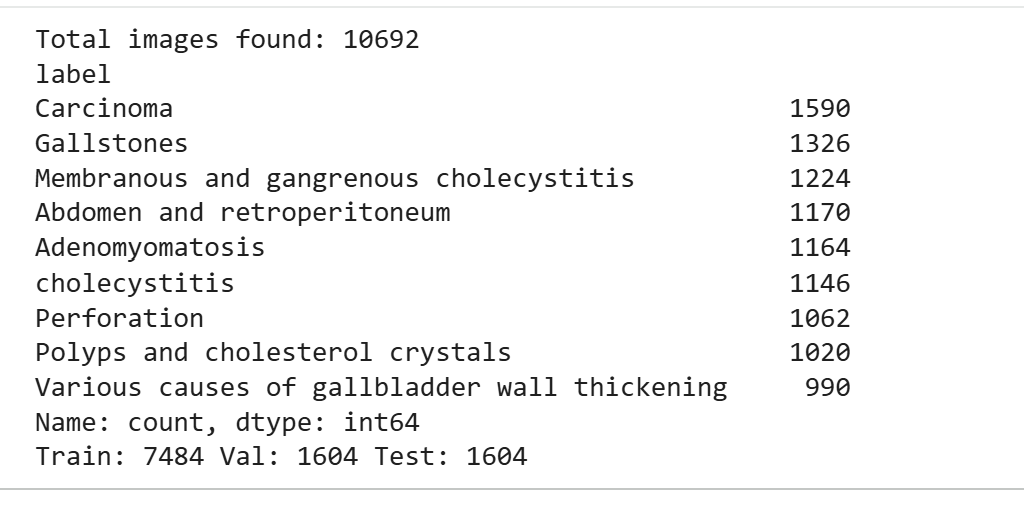

In [ ]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

records = []
for cls in CLASS_NAMES:
    cls_root = os.path.join(DATA_DIR, cls)
    for root, dirs, files in os.walk(cls_root):
        for fname in files:
            if os.path.splitext(fname)[1].lower() in VALID_EXTS:
                records.append({"filepath": os.path.join(root, fname), "label": cls})

df = pd.DataFrame(records)
print("Total images found:", len(df))

if len(df) == 0:
    raise RuntimeError(
        "0 images found -- inspect DATA_DIR / CLASS_NAMES with an os.walk on one "
        "class folder to see the actual structure before continuing."
    )

print(df["label"].value_counts())

le = LabelEncoder()
df["y"] = le.fit_transform(df["label"])

df_train, df_temp = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=RANDOM_STATE)
df_val, df_test = train_test_split(df_temp, test_size=0.50, stratify=df_temp["y"], random_state=RANDOM_STATE)

print("Train:", len(df_train), "Val:", len(df_val), "Test:", len(df_test))


In [ ]:
# --- GRAPH: class distribution across the full dataset ---
plt.figure(figsize=(10, 5))
df["label"].value_counts().sort_values(ascending=False).plot(kind="bar", color="#4C72B0")
plt.title("Class distribution — full dataset")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Step 3 — Deep Learning models (runs first — no feature extraction needed)

Fine-tune four ImageNet-pretrained backbones directly on the raw images: **MobileNetV3Large, ResNet50, DenseNet121, EfficientNetB3**. Two-phase strategy: train a new classification head with the backbone frozen, then unfreeze the top ~30 layers and fine-tune at a low learning rate. `class_weight` is applied in both phases. Training history from both phases is captured for the training-curve plots below.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

DL_CONFIGS = {
    "MobileNetV3": {
        "size": 224,
        "build": lambda inp: MobileNetV3Large(include_top=False, weights="imagenet", input_tensor=inp, pooling="avg"),
        "preprocess": mobilenet_v3.preprocess_input,
    },
    "ResNet50": {
        "size": 224,
        "build": lambda inp: resnet50.ResNet50(include_top=False, weights="imagenet", input_tensor=inp, pooling="avg"),
        "preprocess": resnet50.preprocess_input,
    },
    "DenseNet121": {
        "size": 224,
        "build": lambda inp: densenet.DenseNet121(include_top=False, weights="imagenet", input_tensor=inp, pooling="avg"),
        "preprocess": densenet.preprocess_input,
    },
    "EfficientNetB3": {
        "size": 300,
        "build": lambda inp: efficientnet.EfficientNetB3(include_top=False, weights="imagenet", input_tensor=inp, pooling="avg"),
        "preprocess": efficientnet.preprocess_input,
    },
}

NUM_CLASSES = len(CLASS_NAMES)

def make_dataset(df_split, size, preprocess_fn, training=False):
    paths = df_split["filepath"].values
    labels = df_split["y"].values

    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        img = tf.image.resize(img, (size, size))
        img = preprocess_fn(img)
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=RANDOM_STATE)
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
    if training:
        def augment(img, label):
            img = tf.image.random_flip_left_right(img)
            img = tf.image.random_brightness(img, 0.1)
            return img, label
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


In [ ]:
class_weight_arr = compute_class_weight("balanced", classes=np.unique(df_train["y"]), y=df_train["y"])
class_weight_dict = dict(enumerate(class_weight_arr))
print(class_weight_dict)


In [ ]:
def build_and_train(name, cfg, epochs_head=8, epochs_finetune=6):
    size = cfg["size"]
    train_ds = make_dataset(df_train, size, cfg["preprocess"], training=True)
    val_ds   = make_dataset(df_val, size, cfg["preprocess"], training=False)
    test_ds  = make_dataset(df_test, size, cfg["preprocess"], training=False)

    inp = layers.Input(shape=(size, size, 3))
    base = cfg["build"](inp)
    base.trainable = False

    x = layers.Dropout(0.3)(base.output)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(inp, out, name=name)

    model.compile(optimizer=optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    callbacks = [
        tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_accuracy"),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, monitor="val_loss"),
    ]

    print(f"\n--- {name}: training classification head ---")
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_head,
                       callbacks=callbacks, verbose=1, class_weight=class_weight_dict)

    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False

    model.compile(optimizer=optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    print(f"--- {name}: fine-tuning top layers ---")
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_finetune,
                       callbacks=callbacks, verbose=1, class_weight=class_weight_dict)

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    y_true = df_test["y"].values
    f1 = f1_score(y_true, y_pred, average="macro")

    print(f"{name} — Test accuracy: {test_acc:.4f} | Macro F1: {f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=le.classes_))

    combined_history = {
        "accuracy": hist1.history["accuracy"] + hist2.history["accuracy"],
        "val_accuracy": hist1.history["val_accuracy"] + hist2.history["val_accuracy"],
        "loss": hist1.history["loss"] + hist2.history["loss"],
        "val_loss": hist1.history["val_loss"] + hist2.history["val_loss"],
        "phase_split": len(hist1.history["accuracy"]),
    }

    return {"model": model, "accuracy": test_acc, "macro_f1": f1,
            "y_true": y_true, "y_pred": y_pred, "history": combined_history}


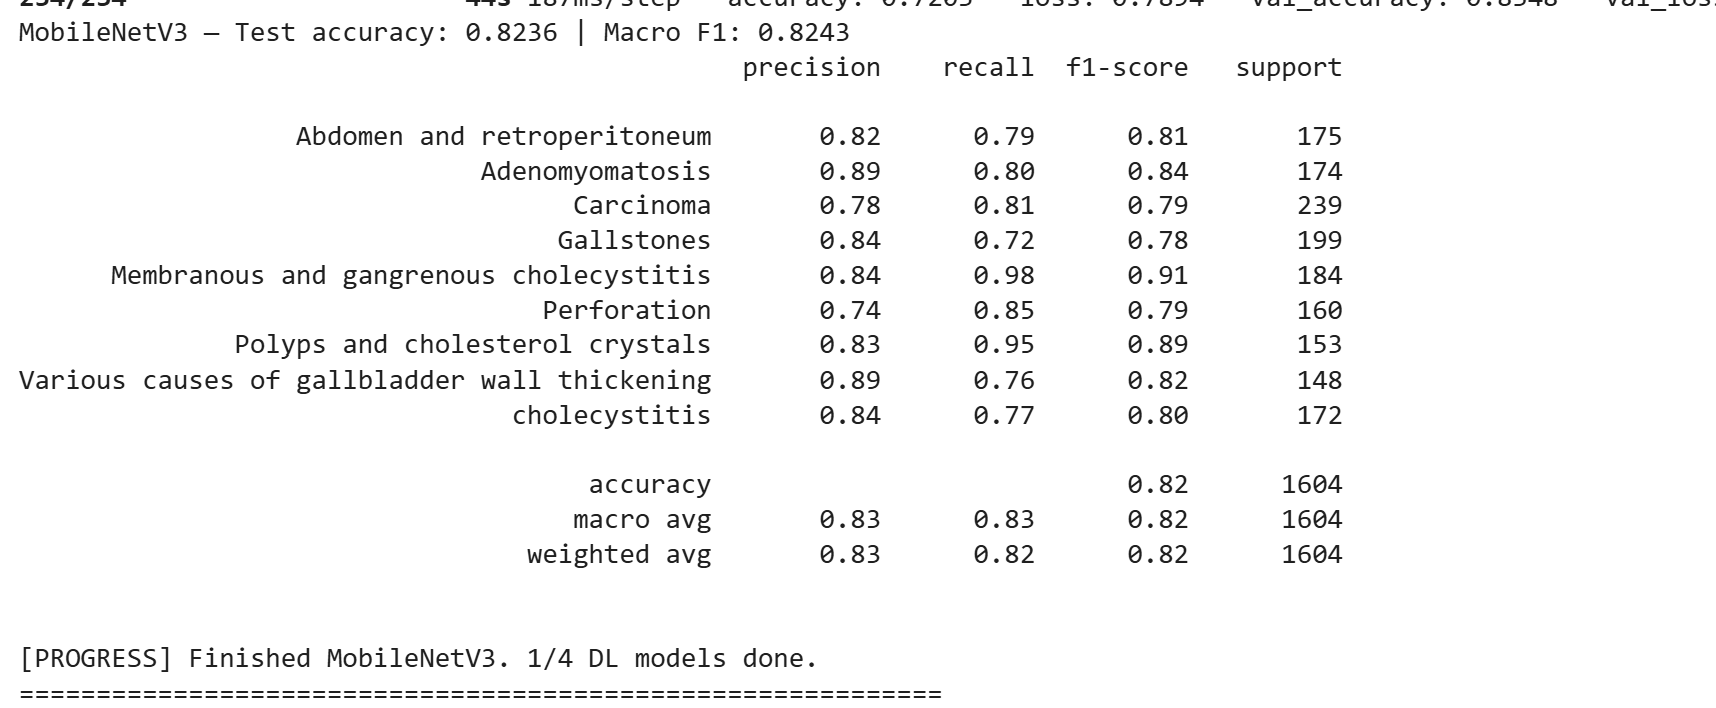

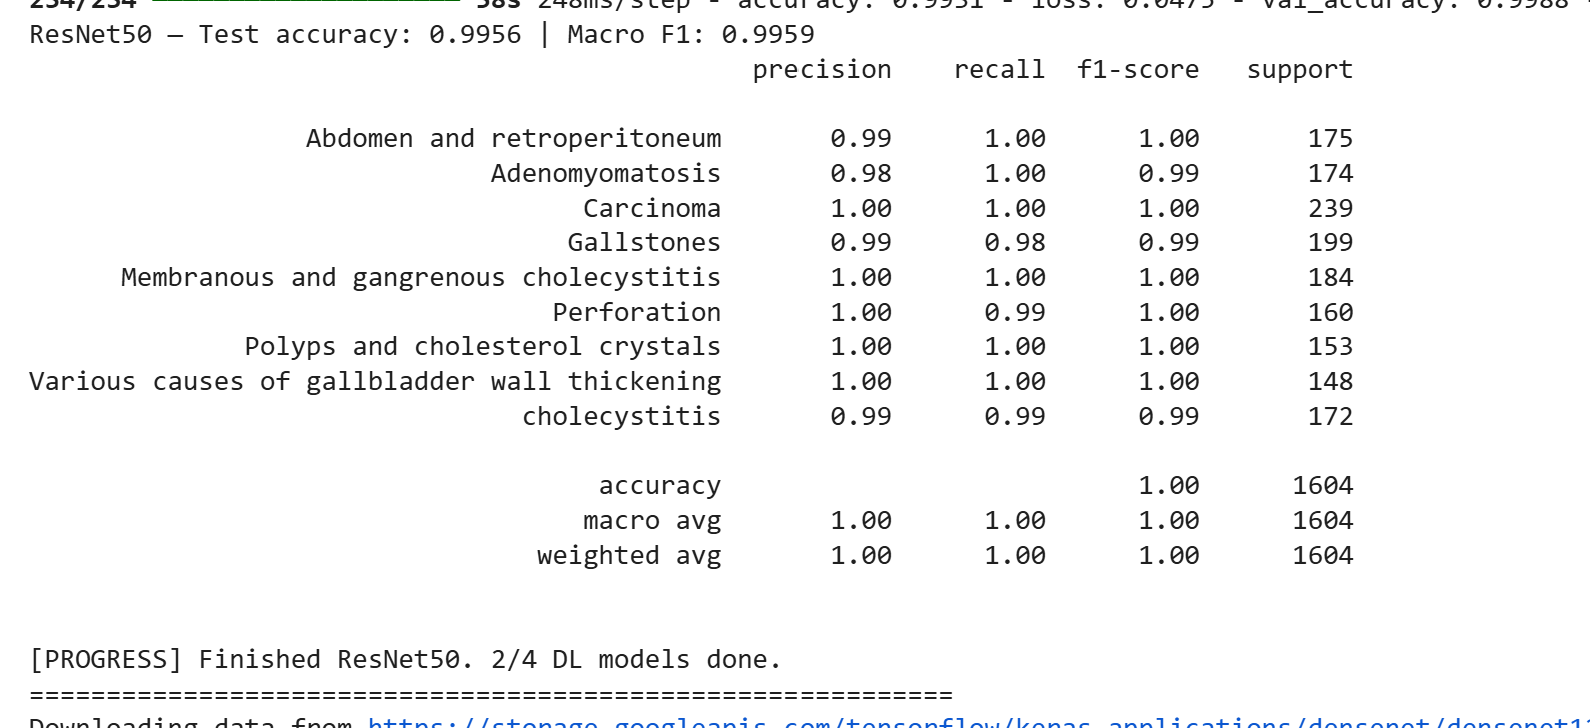

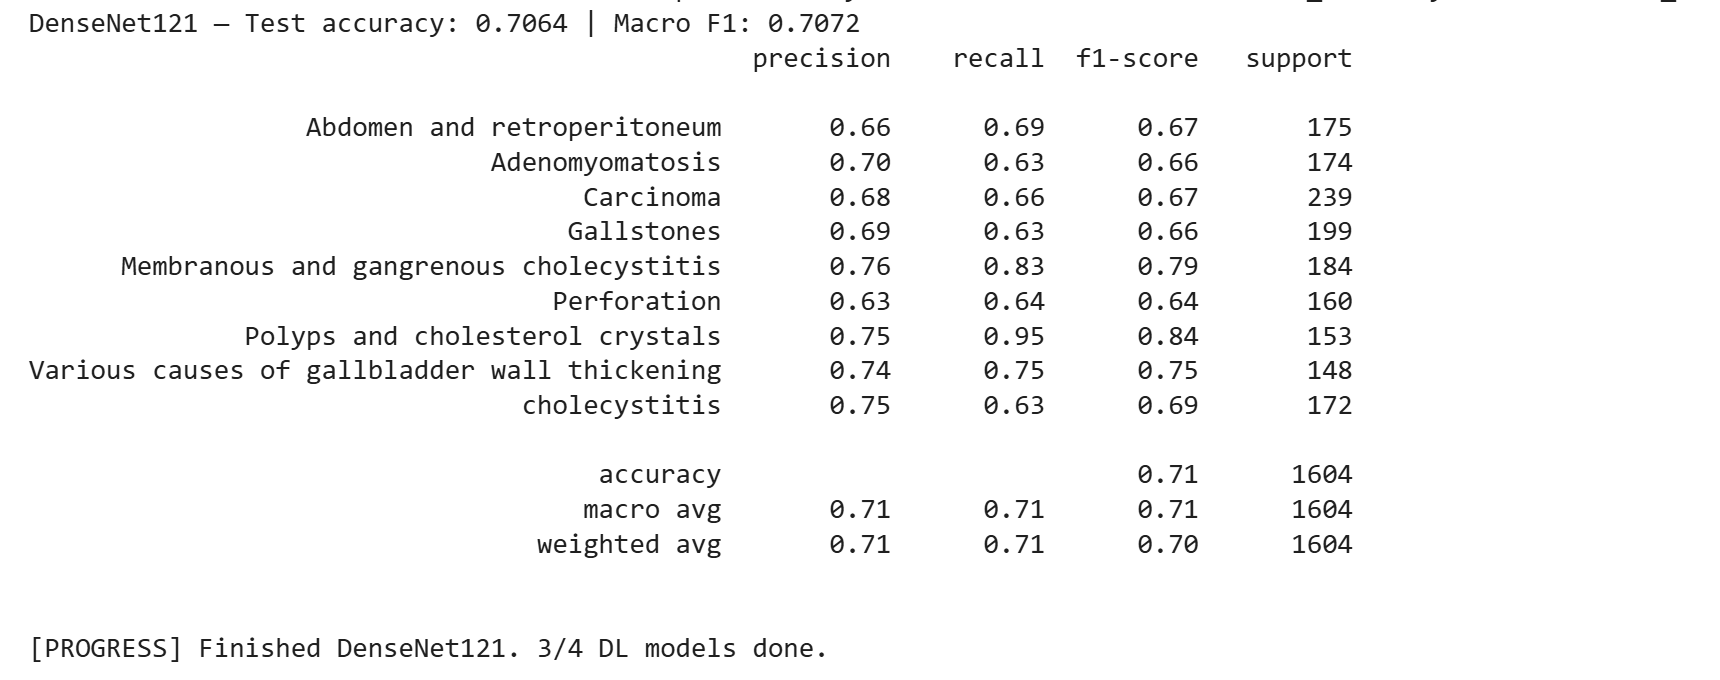

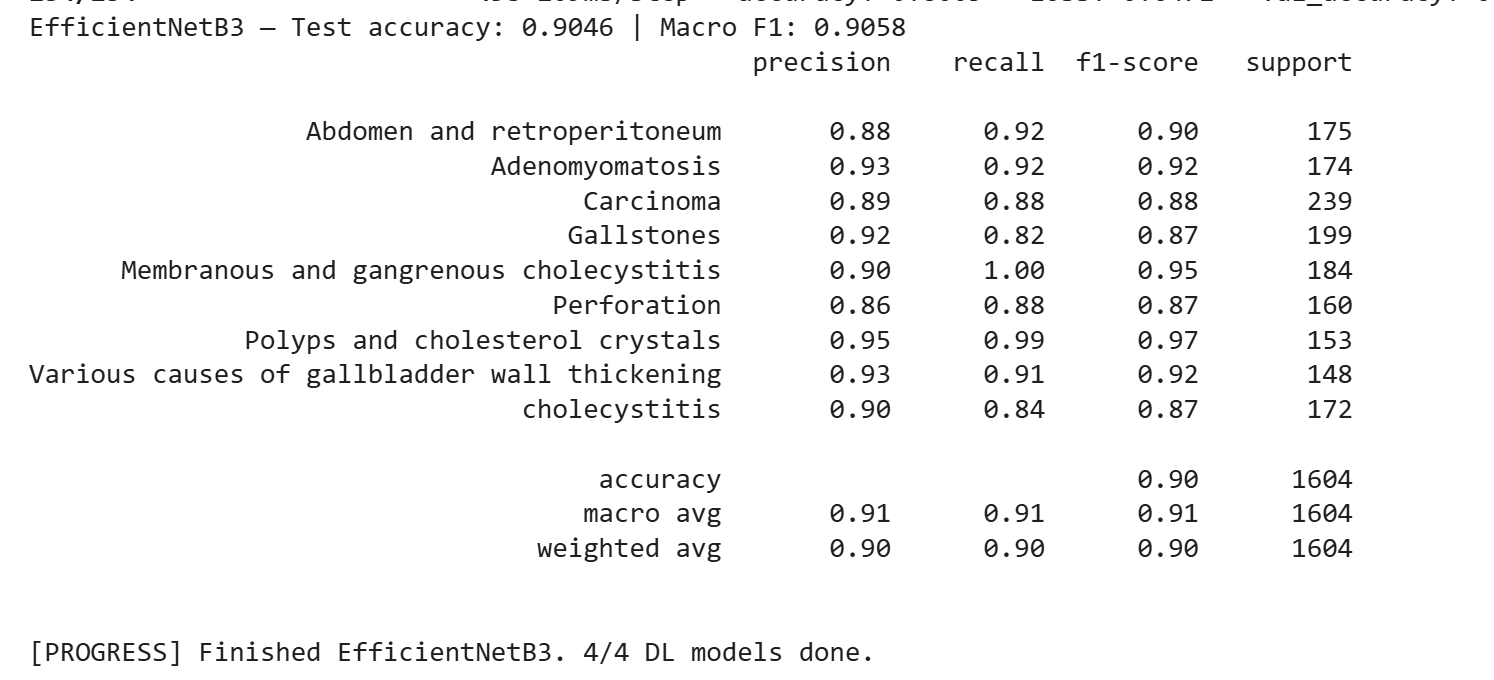

In [ ]:
dl_results = {}
for name, cfg in DL_CONFIGS.items():
    dl_results[name] = build_and_train(name, cfg)
    print(f"\n[PROGRESS] Finished {name}. {len(dl_results)}/{len(DL_CONFIGS)} DL models done.\n" + "="*60)


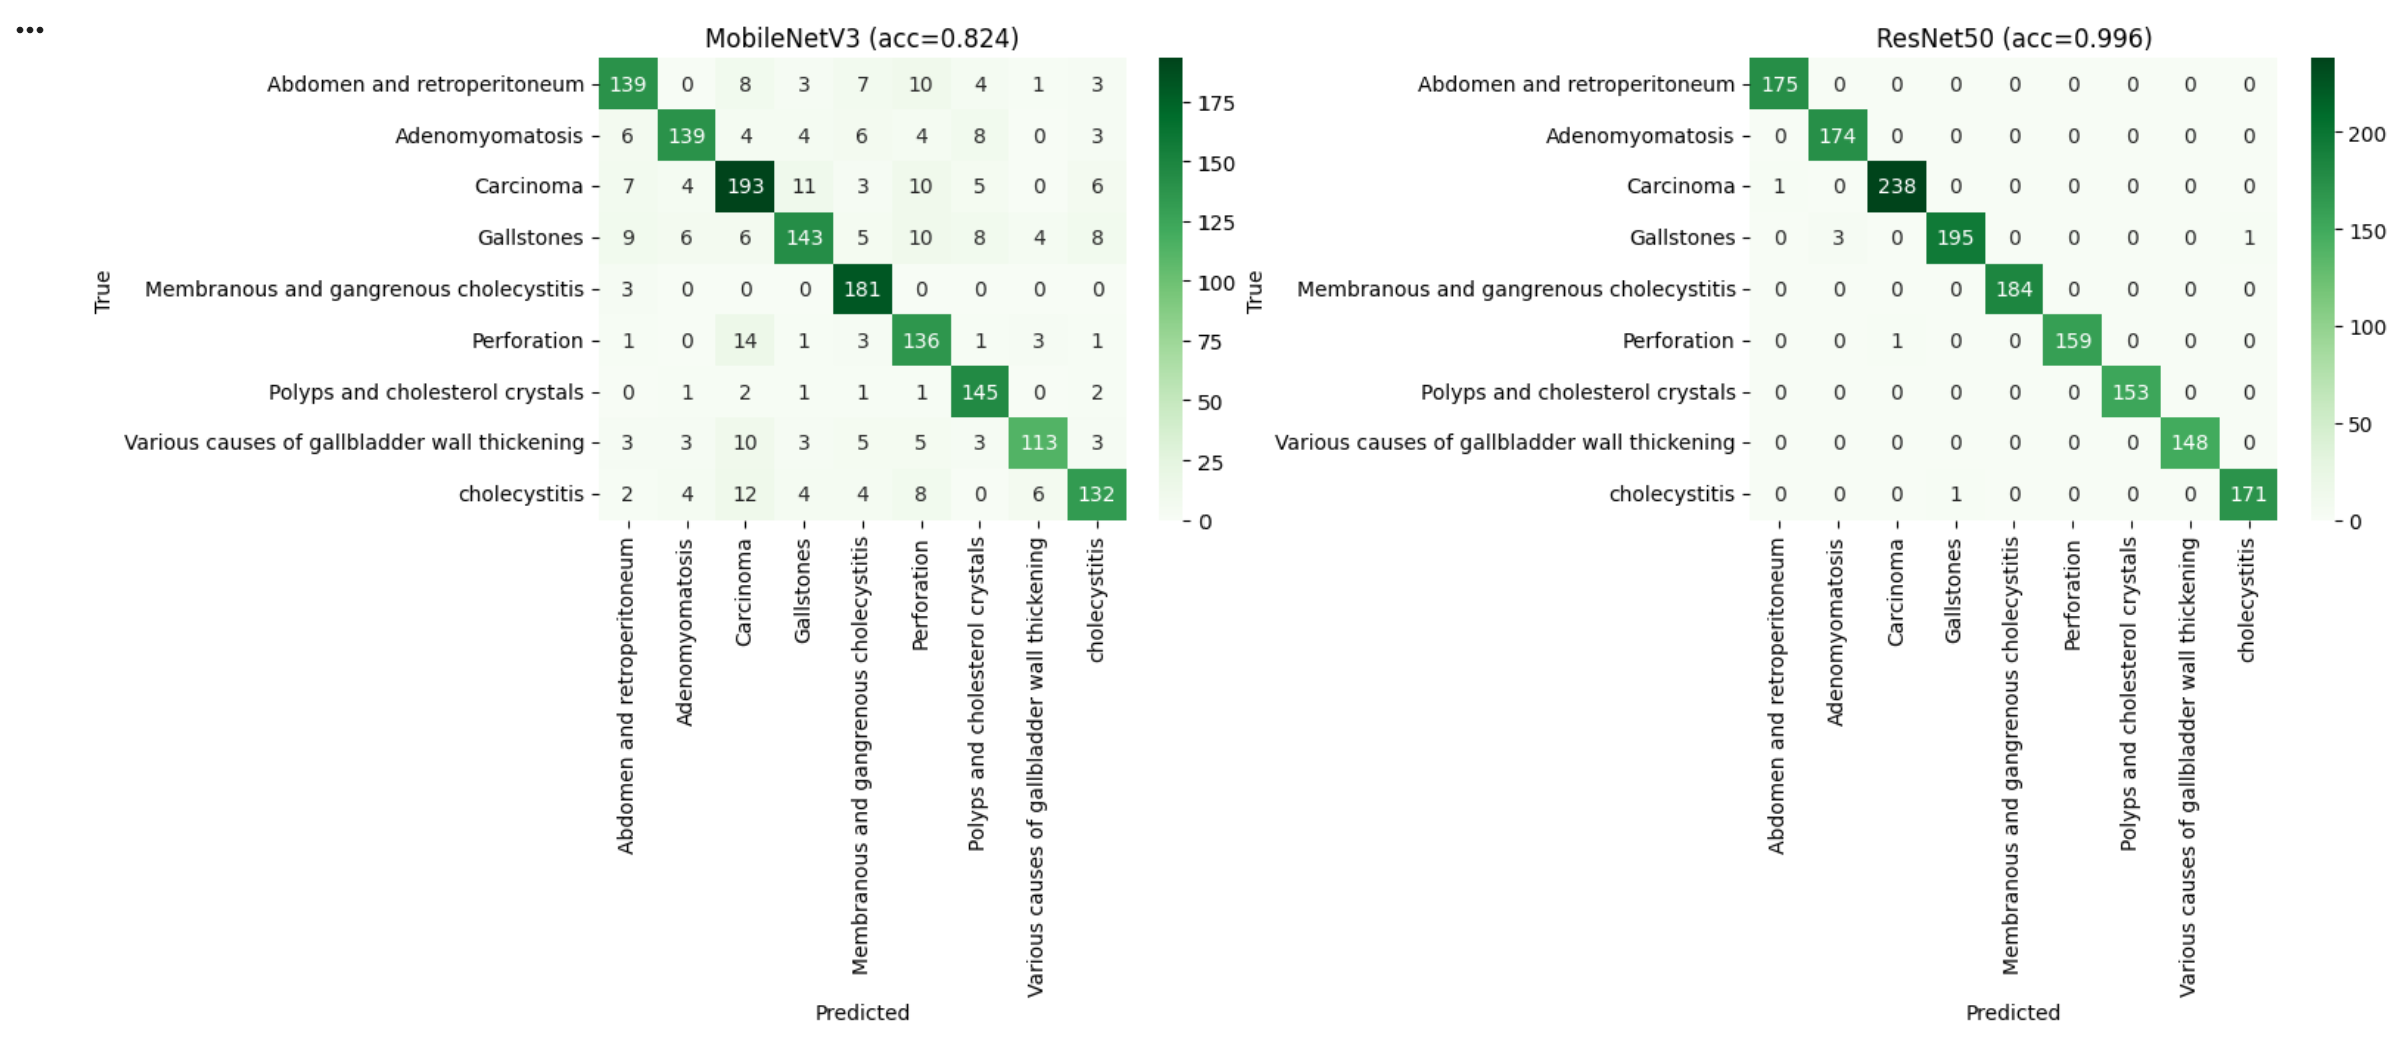

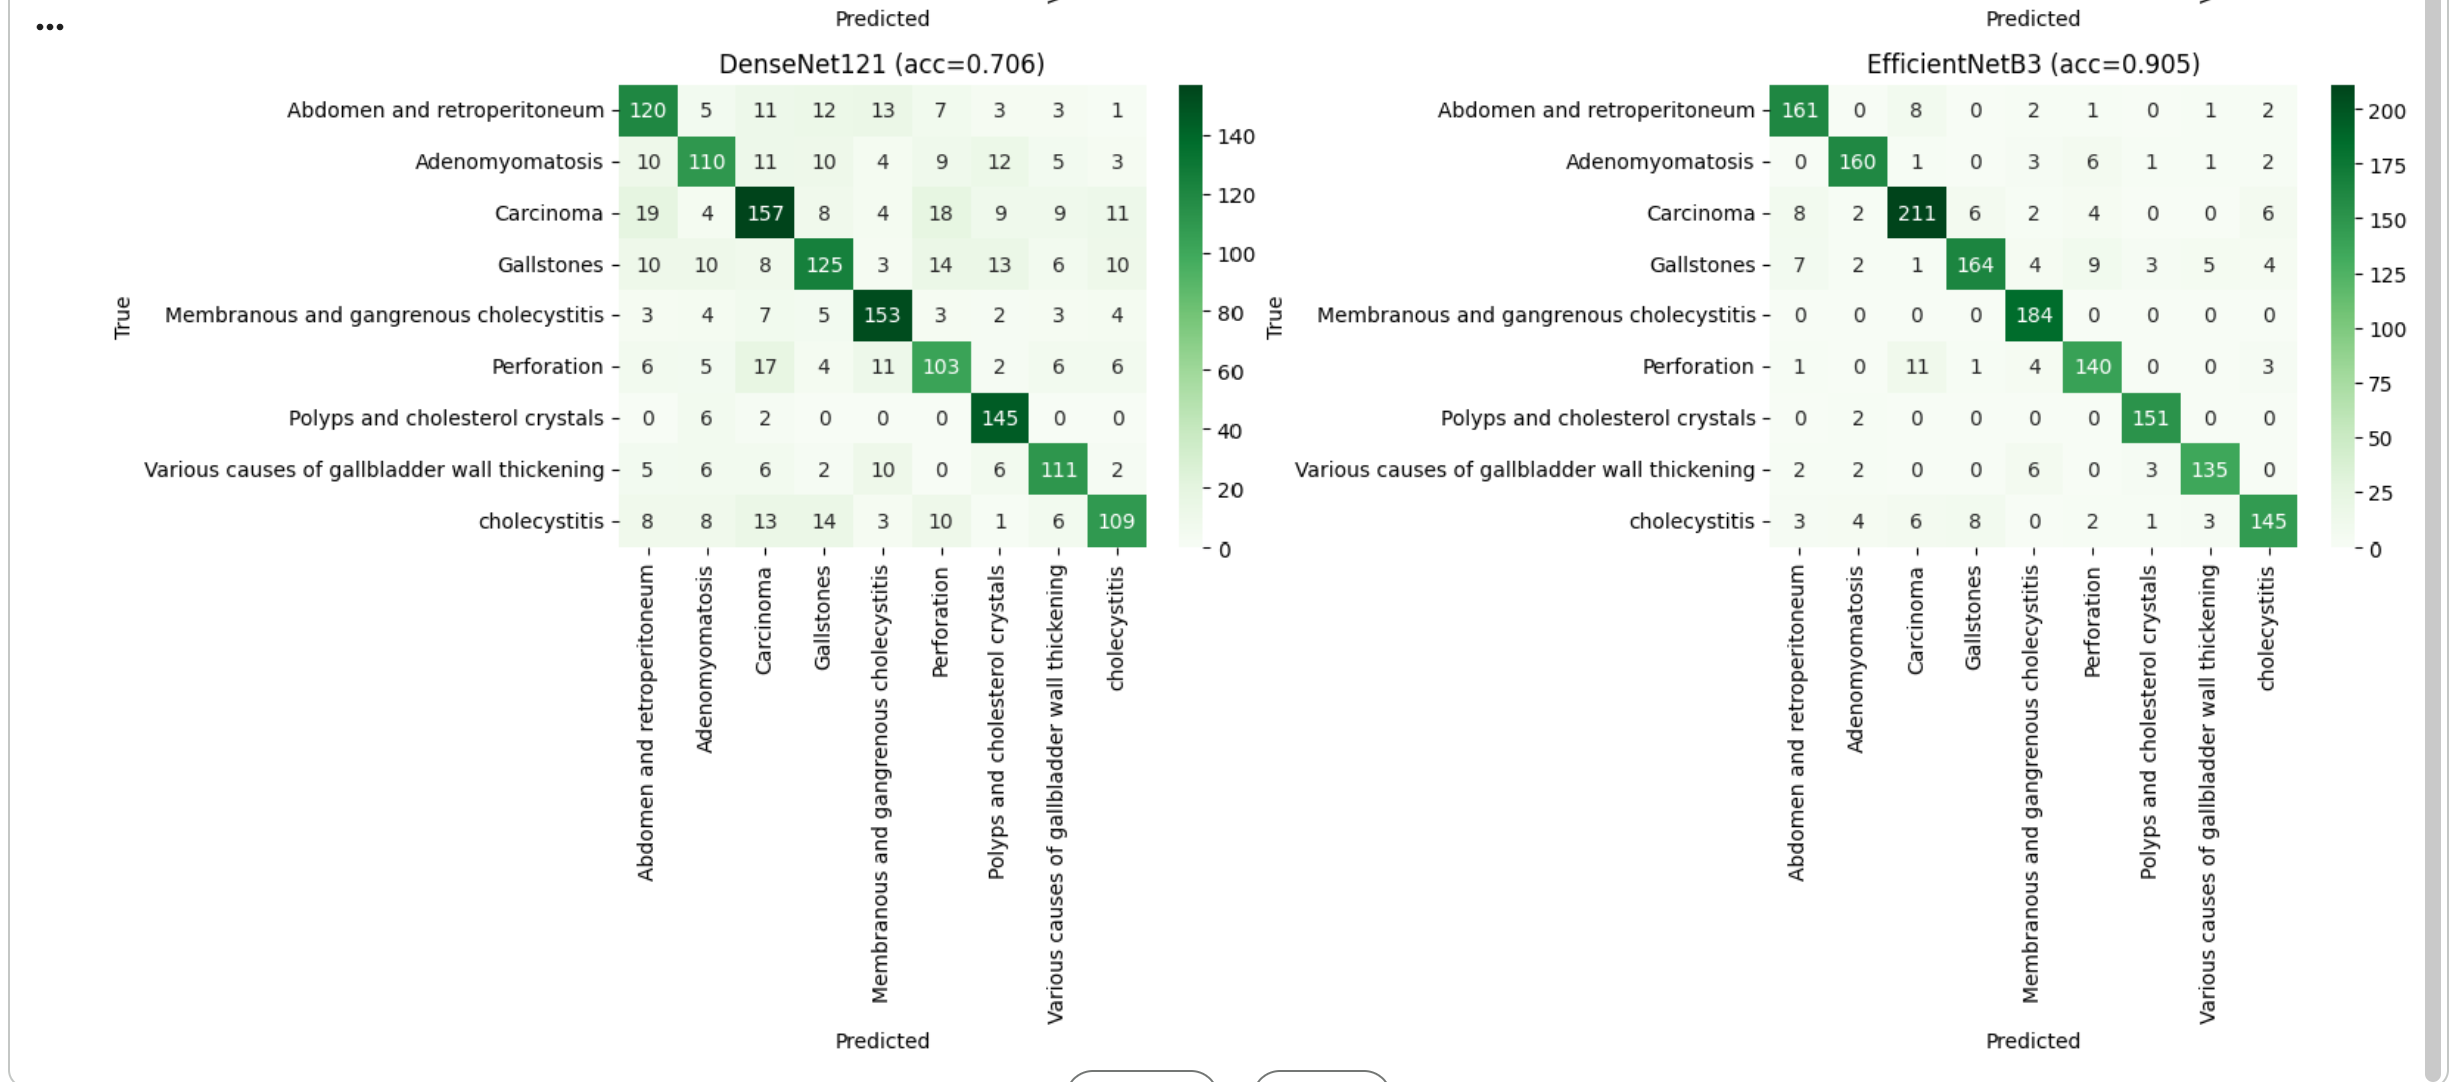

In [ ]:
# --- GRAPH: confusion matrices for all DL models ---
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, (name, res) in zip(axes.ravel(), dl_results.items()):
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(f"{name} (acc={res['accuracy']:.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
# --- GRAPH: DL training curves (accuracy + loss per epoch, phase split marked) ---
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
for col, (name, res) in enumerate(dl_results.items()):
    h = res["history"]
    epochs_range = range(1, len(h["accuracy"]) + 1)

    axes[0, col].plot(epochs_range, h["accuracy"], label="train")
    axes[0, col].plot(epochs_range, h["val_accuracy"], label="val")
    axes[0, col].axvline(h["phase_split"], color="gray", linestyle="--", alpha=0.6)
    axes[0, col].set_title(f"{name} — Accuracy")
    axes[0, col].legend(); axes[0, col].set_xlabel("Epoch")

    axes[1, col].plot(epochs_range, h["loss"], label="train")
    axes[1, col].plot(epochs_range, h["val_loss"], label="val")
    axes[1, col].axvline(h["phase_split"], color="gray", linestyle="--", alpha=0.6)
    axes[1, col].set_title(f"{name} — Loss")
    axes[1, col].legend(); axes[1, col].set_xlabel("Epoch")

plt.tight_layout()
plt.show()


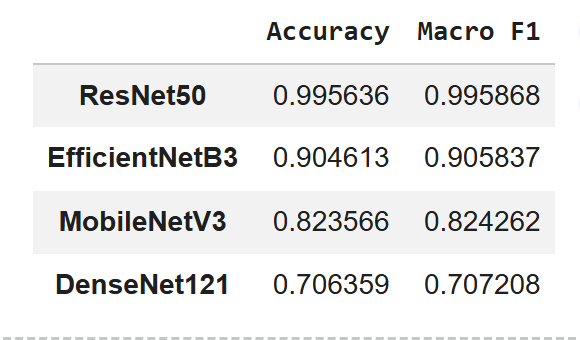

In [ ]:
dl_summary = pd.DataFrame({
    name: {"Accuracy": res["accuracy"], "Macro F1": res["macro_f1"]}
    for name, res in dl_results.items()
}).T.sort_values("Accuracy", ascending=False)
dl_summary


In [ ]:
# Save the lightweight parts of dl_results (skip the full model objects — those are large)
dl_results_light = {
    name: {
        "accuracy": res["accuracy"],
        "macro_f1": res["macro_f1"],
        "y_true": res["y_true"].tolist(),
        "y_pred": res["y_pred"].tolist(),
        "history": res["history"],
    }
    for name, res in dl_results.items()
}

with open(os.path.join(CHECKPOINT_DIR, "dl_results.pkl"), "wb") as f:
    pickle.dump(dl_results_light, f)
print("Saved DL results (metrics/history, not full models) to Drive checkpoint.")

# Now clear the heavy stuff from memory
del dl_results
tf.keras.backend.clear_session()
gc.collect()
print("Cleared DL models, TF session, and freed memory.")


## Step 4 — Feature extraction (for the classical ML models)

Combined per-image feature vector out of four descriptors: **HOG**, **LBP**, **GLCM**, and **ResNet50 embeddings** (2048-d, ImageNet-pretrained, frozen). This section is independent of the DL section above — nothing here depends on `dl_results`.


In [ ]:
IMG_SIZE = 224

def load_image(filepath, size=IMG_SIZE):
    img = cv2.imread(filepath)
    if img is None:
        img = np.array(tf.keras.utils.load_img(filepath, target_size=(size, size)))
        return img
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img

def extract_hog(gray_img):
    return hog(gray_img, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)

def extract_lbp(gray_img, P=8, R=1, n_bins=59):
    lbp = local_binary_pattern((gray_img * 255).astype(np.uint8), P, R, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist

def extract_glcm(gray_img, distances=(1, 2), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    img8 = (gray_img * 255).astype(np.uint8)
    glcm = graycomatrix(img8, distances=list(distances), angles=list(angles),
                         levels=256, symmetric=True, normed=True)
    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    return np.hstack([graycoprops(glcm, p).ravel() for p in props])


In [ ]:
resnet_feat_extractor = resnet50.ResNet50(weights="imagenet", include_top=False, pooling="avg",
                                           input_shape=(IMG_SIZE, IMG_SIZE, 3))
resnet_feat_extractor.trainable = False

def extract_resnet_embeddings_batch(filepaths, batch_size=32):
    embeddings = []
    for i in tqdm(range(0, len(filepaths), batch_size), desc="ResNet50 embeddings"):
        batch_paths = filepaths[i:i+batch_size]
        batch_imgs = np.stack([load_image(fp) for fp in batch_paths]).astype(np.float32)
        batch_imgs = resnet50.preprocess_input(batch_imgs)
        embeddings.append(resnet_feat_extractor.predict(batch_imgs, verbose=0))
    return np.vstack(embeddings)


In [ ]:
def extract_handcrafted_features(filepaths):
    hog_feats, lbp_feats, glcm_feats = [], [], []
    for fp in tqdm(filepaths, desc="HOG/LBP/GLCM"):
        img = load_image(fp)
        gray = rgb2gray(img)
        hog_feats.append(extract_hog(gray))
        lbp_feats.append(extract_lbp(gray))
        glcm_feats.append(extract_glcm(gray))
    return np.array(hog_feats), np.array(lbp_feats), np.array(glcm_feats)


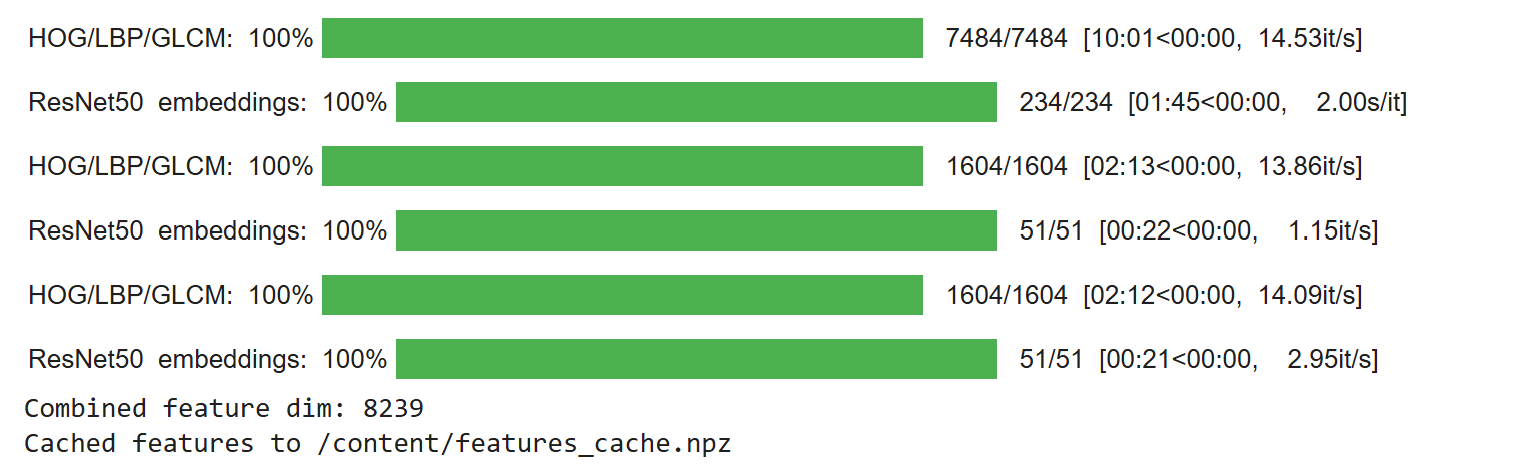

In [ ]:
def build_feature_matrix(df_split):
    filepaths = df_split["filepath"].tolist()
    hog_f, lbp_f, glcm_f = extract_handcrafted_features(filepaths)
    resnet_f = extract_resnet_embeddings_batch(filepaths)
    combined = np.hstack([hog_f, lbp_f, glcm_f, resnet_f])
    return {"hog": hog_f, "lbp": lbp_f, "glcm": glcm_f, "resnet50": resnet_f,
            "combined": combined, "y": df_split["y"].values}

feats_train = build_feature_matrix(df_train)
feats_val   = build_feature_matrix(df_val)
feats_test  = build_feature_matrix(df_test)

print("Combined feature dim:", feats_train["combined"].shape[1])

np.savez("/content/features_cache.npz",
         Xtr=feats_train["combined"], ytr=feats_train["y"],
         Xval=feats_val["combined"], yval=feats_val["y"],
         Xte=feats_test["combined"], yte=feats_test["y"])
print("Cached features to /content/features_cache.npz")


## Step 5 — Classical ML models on the extracted features

Standardize the combined feature vector, then train six classifiers with **class-weighting**. SVM has `probability=True` removed for speed. LightGBM uses `max_bin=63`, `force_row_wise=True`, and `n_jobs=4` to keep its RAM footprint low (this, combined with the memory cleanup after Step 3, is what fixes the earlier crash). Each model's metrics are checkpointed to Drive right after it finishes.


In [ ]:
scaler = StandardScaler()
Xtr = scaler.fit_transform(feats_train["combined"])
Xval = scaler.transform(feats_val["combined"])
Xte = scaler.transform(feats_test["combined"])
ytr, yval, yte = feats_train["y"], feats_val["y"], feats_test["y"]

print("Xtr shape:", Xtr.shape, "| Xte shape:", Xte.shape)


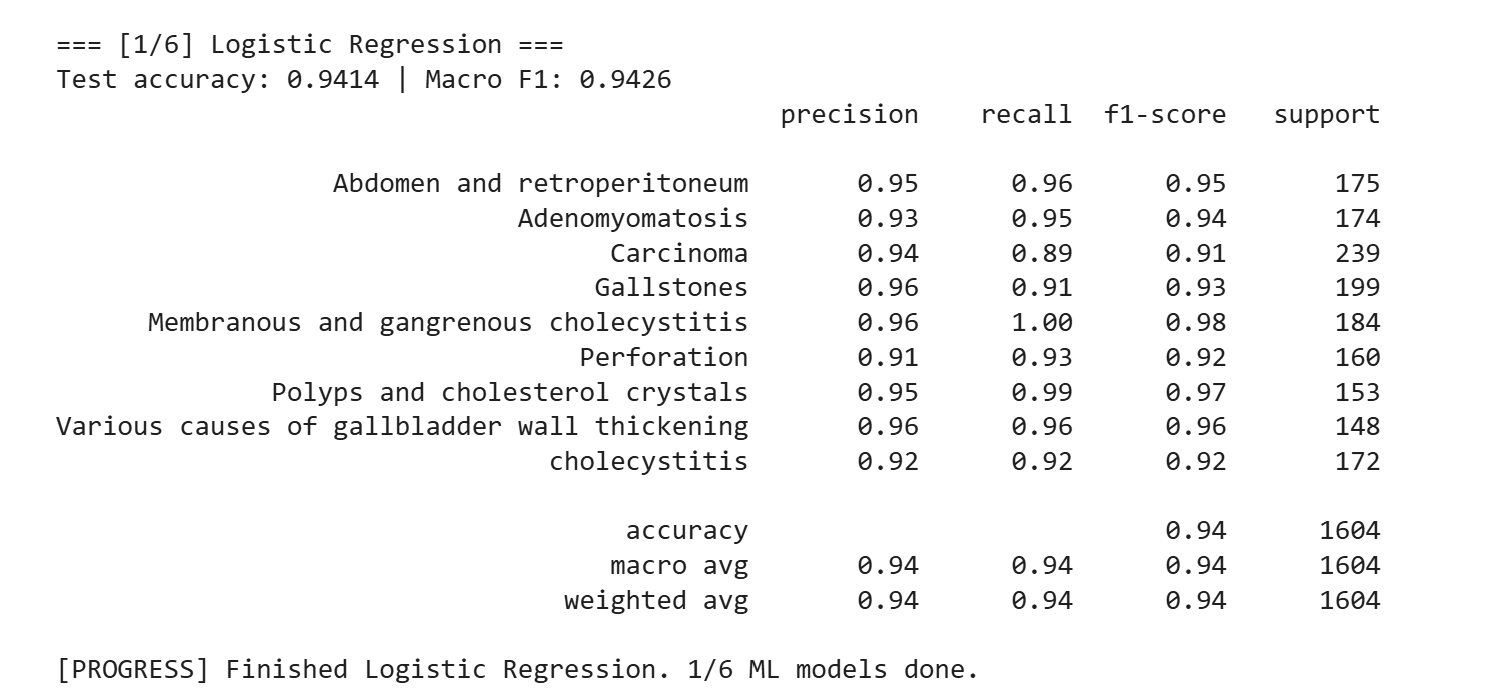

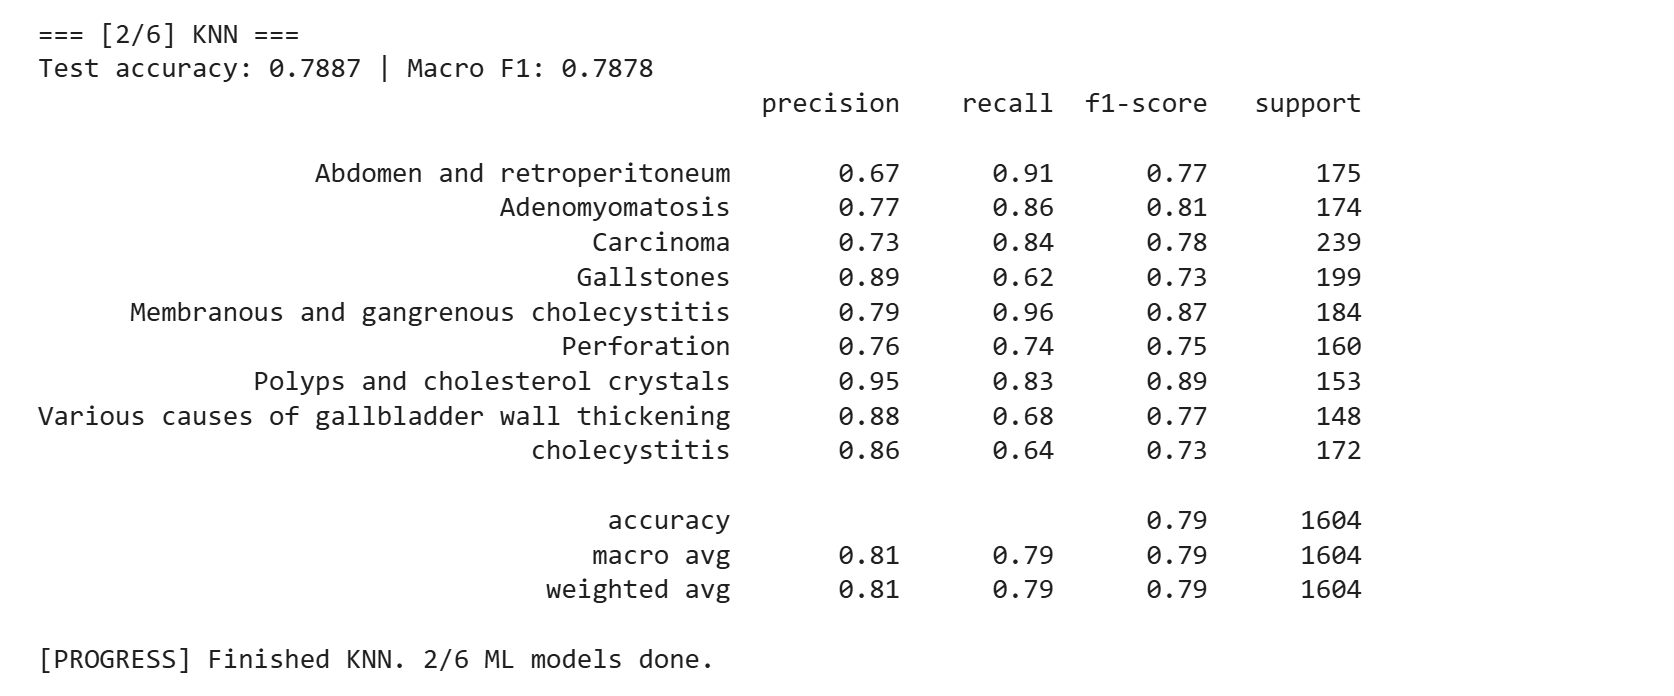

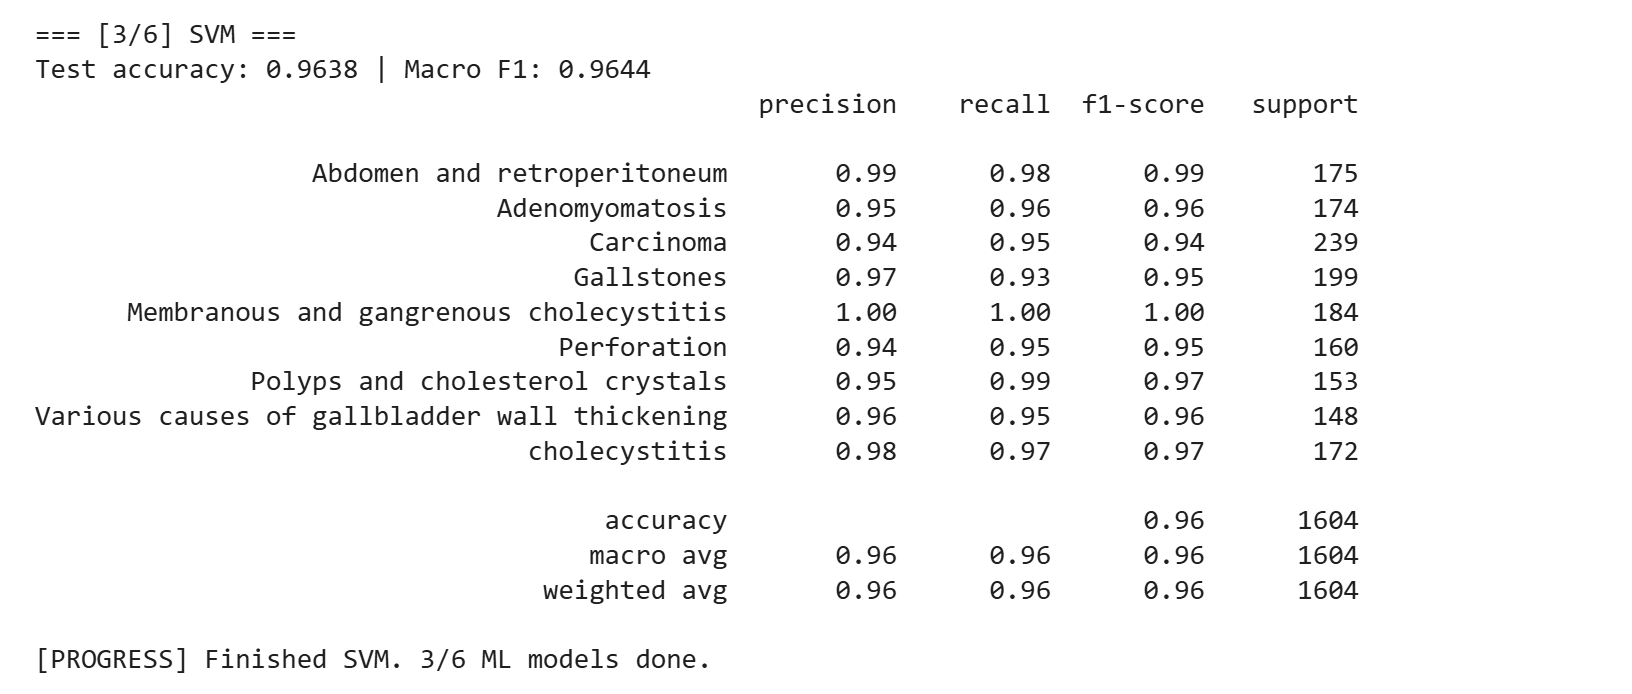

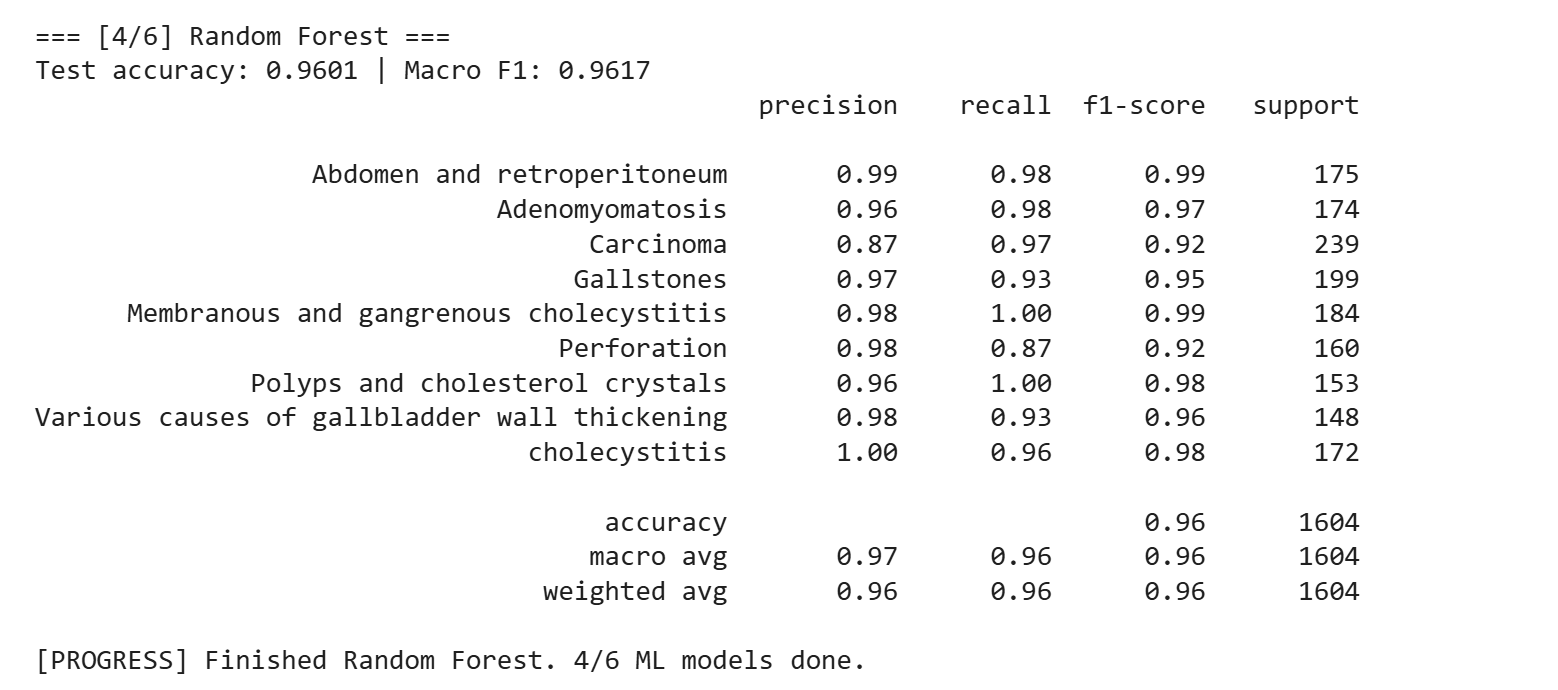

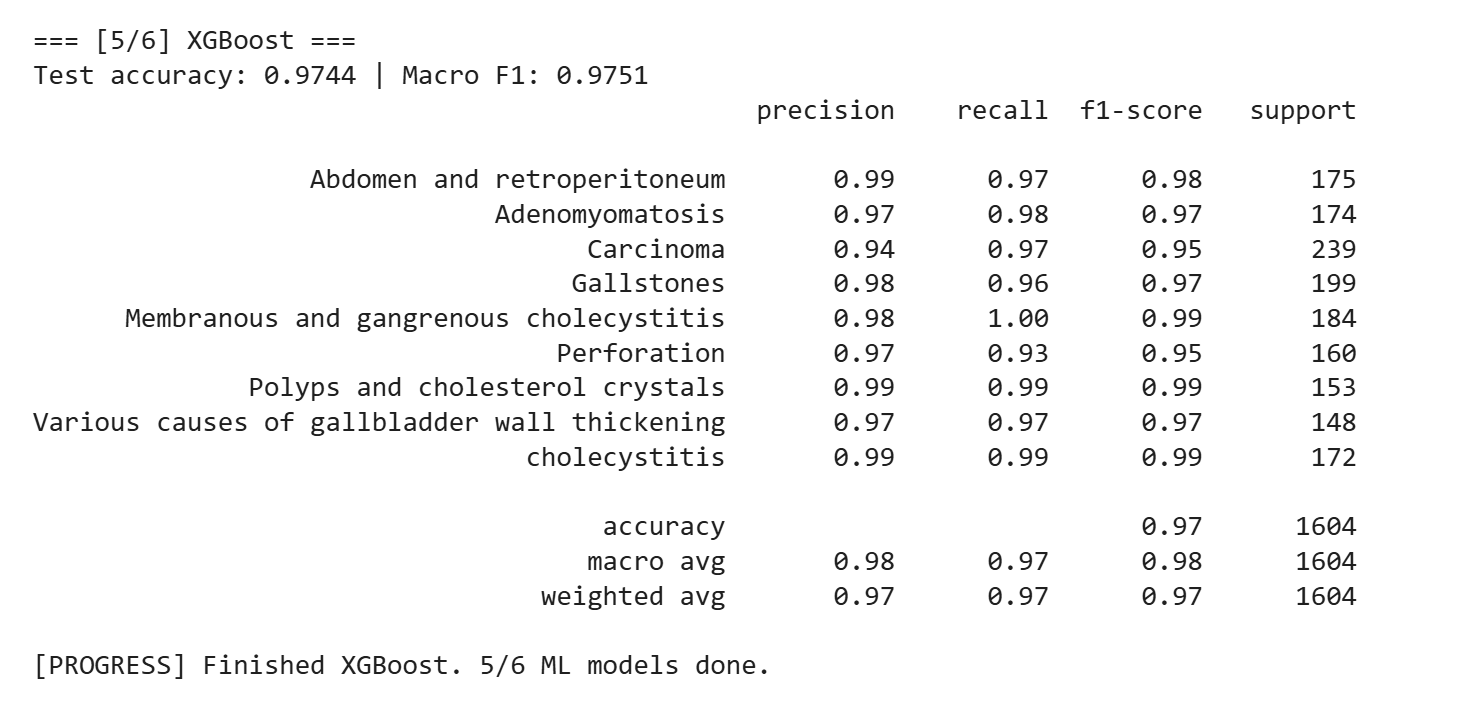

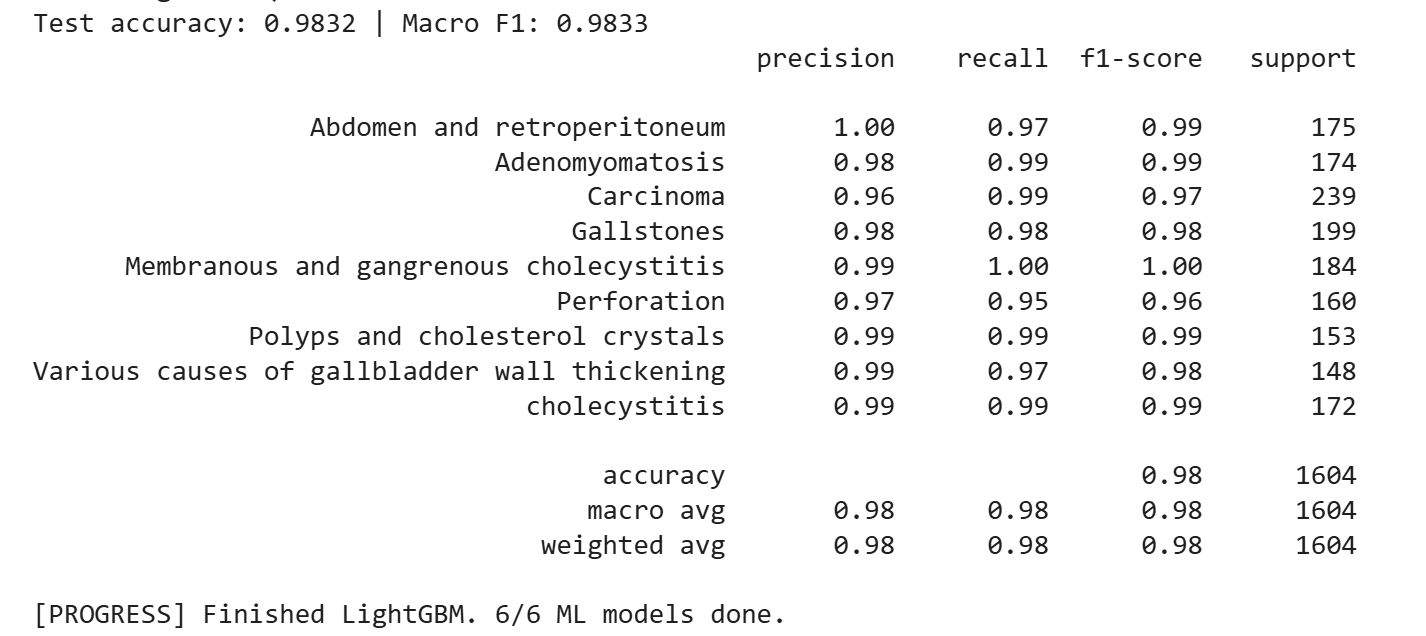

In [ ]:
ml_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM":                 SVC(kernel="rbf", class_weight="balanced", cache_size=1000),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"),
    "XGBoost":             XGBClassifier(n_estimators=300, eval_metric="mlogloss",
                                          random_state=RANDOM_STATE, tree_method="hist"),
    "LightGBM":            LGBMClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced",
                                           verbose=-1, max_bin=63, force_row_wise=True, n_jobs=4),
}

sample_weights = compute_sample_weight(class_weight="balanced", y=ytr)

ml_results = {}
for i, (name, clf) in enumerate(ml_models.items(), start=1):
    print(f"\n=== [{i}/{len(ml_models)}] {name} ===")
    if name == "XGBoost":
        clf.fit(Xtr, ytr, sample_weight=sample_weights)
    else:
        clf.fit(Xtr, ytr)
    preds = clf.predict(Xte)
    acc = accuracy_score(yte, preds)
    f1 = f1_score(yte, preds, average="macro")
    ml_results[name] = {"accuracy": acc, "macro_f1": f1, "model": clf, "preds": preds}
    print(f"Test accuracy: {acc:.4f} | Macro F1: {f1:.4f}")
    print(classification_report(yte, preds, target_names=le.classes_))
    print(f"[PROGRESS] Finished {name}. {i}/{len(ml_models)} ML models done.")

    # checkpoint metrics to Drive after every model
    joblib.dump({"accuracy": acc, "macro_f1": f1},
                os.path.join(CHECKPOINT_DIR, f"ml_result_{name.replace(' ', '_')}.pkl"))


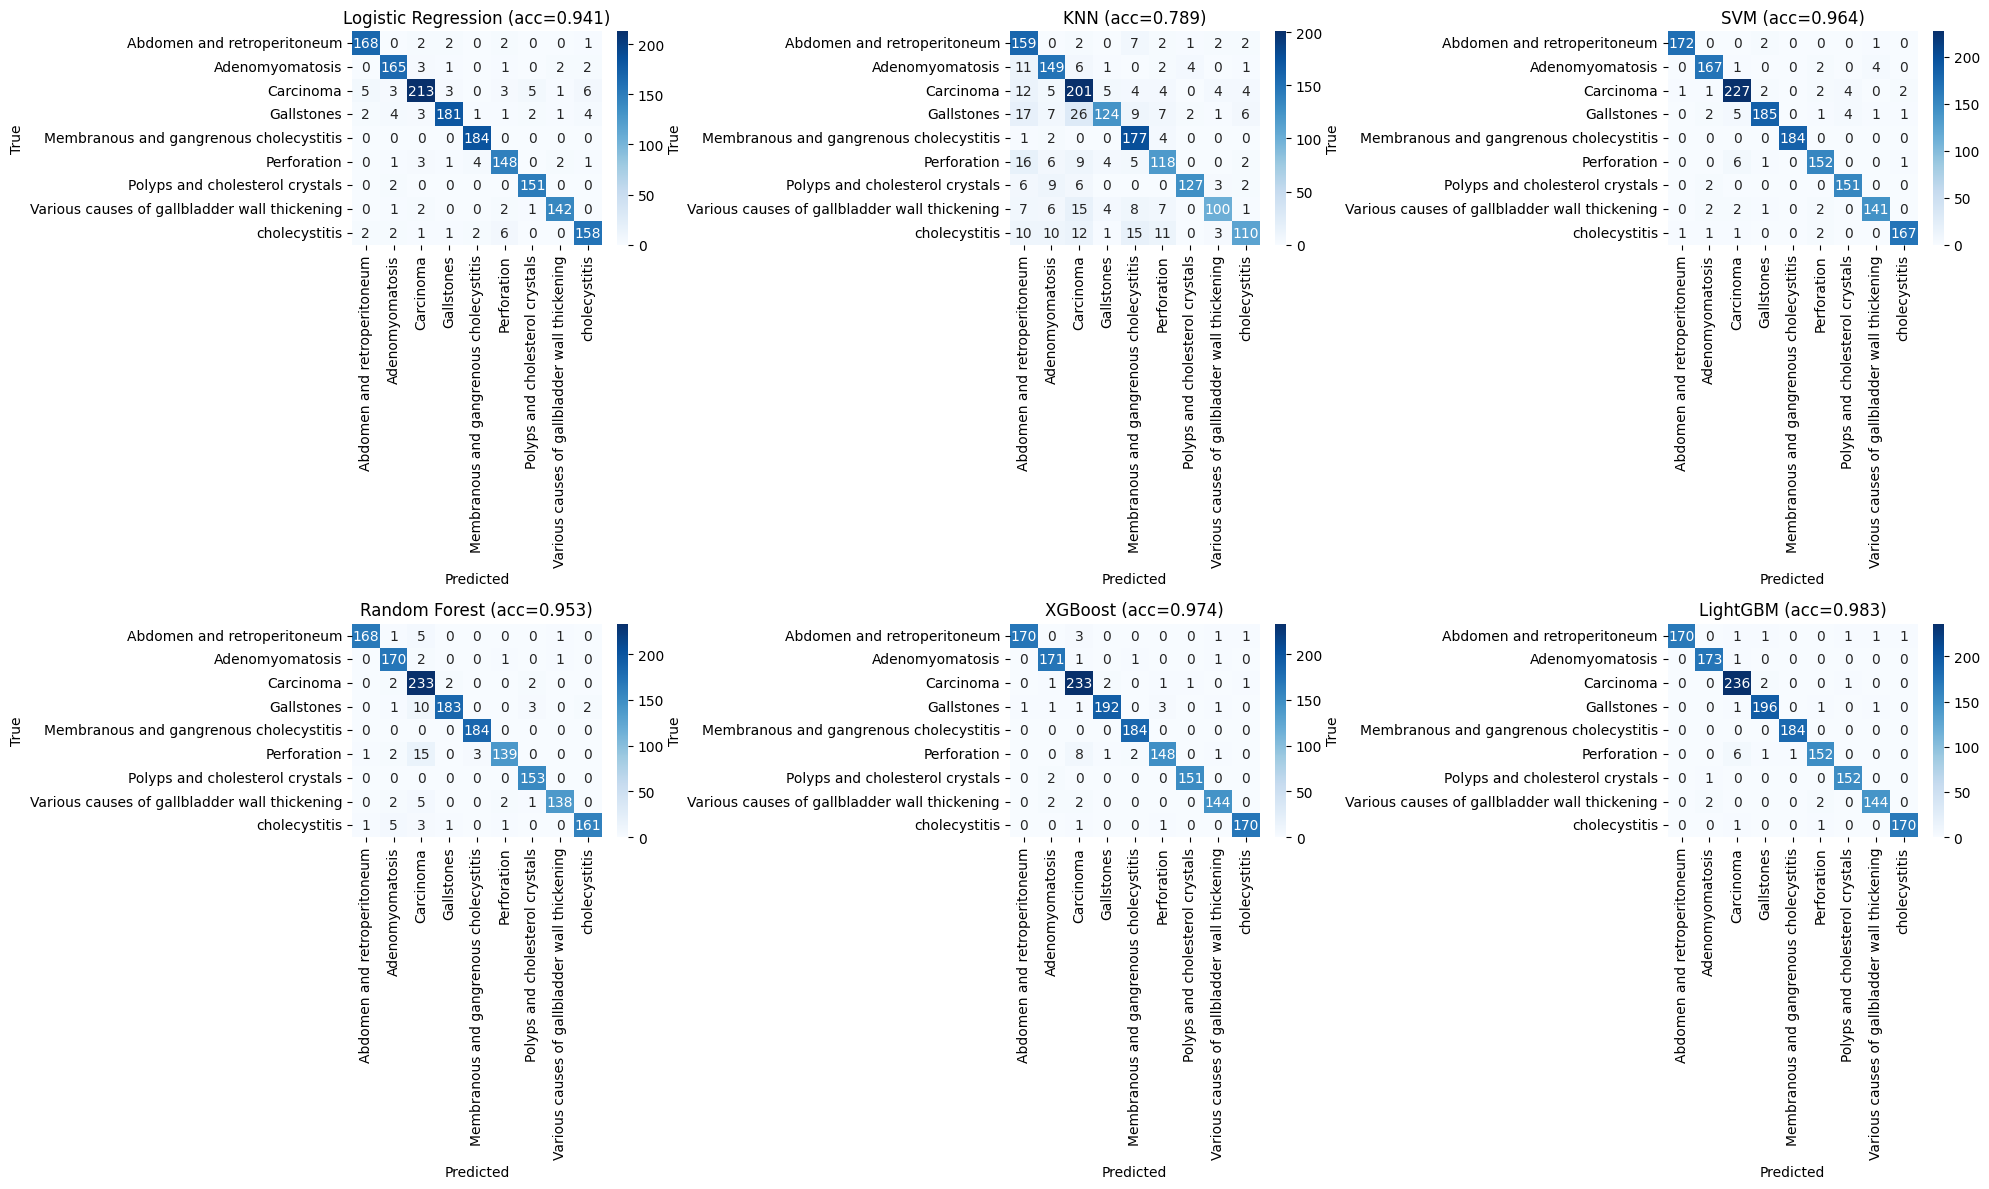

In [ ]:
# --- GRAPH: confusion matrices (normalized, percentages) for all ML models ---
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, (name, res) in zip(axes.ravel(), ml_results.items()):
    cm = confusion_matrix(yte, res["preds"], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_, vmin=0, vmax=1)
    ax.set_title(f"{name} (acc={res['accuracy']:.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()


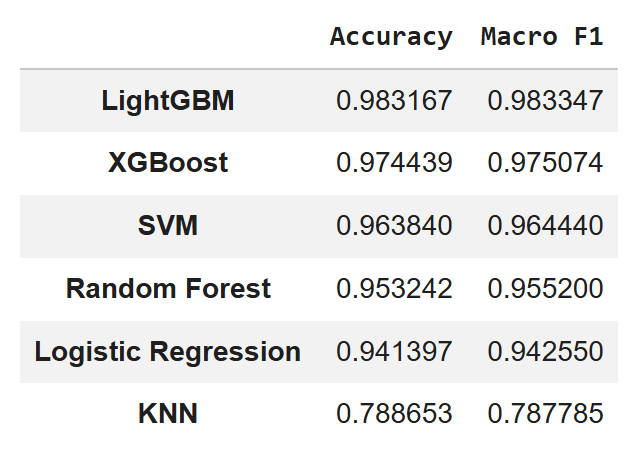

In [ ]:
ml_summary = pd.DataFrame({
    name: {"Accuracy": res["accuracy"], "Macro F1": res["macro_f1"]}
    for name, res in ml_results.items()
}).T.sort_values("Accuracy", ascending=False)
ml_summary


In [ ]:
# --- GRAPH: feature importance by feature type, for tree-based models ---
tree_models = ["Random Forest", "XGBoost", "LightGBM"]
n_hog = feats_train["hog"].shape[1]
n_lbp = feats_train["lbp"].shape[1]
n_glcm = feats_train["glcm"].shape[1]
n_resnet = feats_train["resnet50"].shape[1]

feature_groups = (["HOG"] * n_hog + ["LBP"] * n_lbp + ["GLCM"] * n_glcm + ["ResNet50"] * n_resnet)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, name in zip(axes, tree_models):
    clf = ml_results[name]["model"]
    importances = clf.feature_importances_
    imp_df = pd.DataFrame({"feature_group": feature_groups, "importance": importances})
    group_importance = imp_df.groupby("feature_group")["importance"].sum().sort_values(ascending=False)
    ax.bar(group_importance.index, group_importance.values, color="#55A868")
    ax.set_title(f"{name} — importance by feature type")
    ax.set_ylabel("Summed importance")
plt.tight_layout()
plt.show()


In [ ]:
# --- GRAPH: t-SNE of ResNet50 embeddings (test set) ---
sample_size = min(1500, len(feats_test["resnet50"]))
sample_idx = np.random.choice(len(feats_test["resnet50"]), size=sample_size, replace=False)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init="pca")
embed_2d = tsne.fit_transform(feats_test["resnet50"][sample_idx])

plt.figure(figsize=(10, 8))
labels_sample = feats_test["y"][sample_idx]
scatter = plt.scatter(embed_2d[:, 0], embed_2d[:, 1], c=labels_sample, cmap="tab10", s=15, alpha=0.7)
handles, _ = scatter.legend_elements()
plt.legend(handles, le.classes_, bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.title("t-SNE of ResNet50 embeddings (test set)")
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()


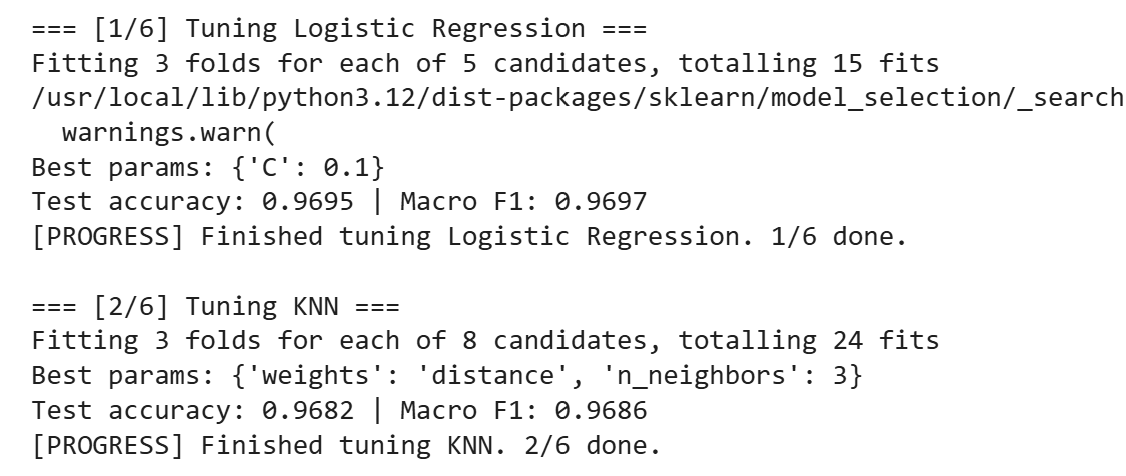

In [ ]:
param_distributions = {
    "Logistic Regression": {"C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"n_neighbors": [3, 5, 7, 9, 11, 15], "weights": ["uniform", "distance"]},
    "SVM": {"C": [0.1, 1, 10, 100], "gamma": ["scale", "auto", 0.001, 0.01]},
    "Random Forest": {"n_estimators": [200, 300, 500], "max_depth": [None, 10, 20, 30],
                       "min_samples_split": [2, 5, 10]},
    "XGBoost": {"n_estimators": [200, 300, 500], "max_depth": [3, 5, 7],
                "learning_rate": [0.01, 0.05, 0.1]},
    "LightGBM": {"n_estimators": [200, 300, 500], "max_depth": [-1, 10, 20],
                 "learning_rate": [0.01, 0.05, 0.1]},
}

tuned_results = {}
for i, (name, clf) in enumerate(ml_models.items(), start=1):
    print(f"\n=== [{i}/{len(ml_models)}] Tuning {name} ===")
    search = RandomizedSearchCV(
        clf, param_distributions[name], n_iter=8, cv=3,
        scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
    )
    if name == "XGBoost":
        search.fit(Xtr, ytr, sample_weight=sample_weights)
    else:
        search.fit(Xtr, ytr)

    best_clf = search.best_estimator_
    preds = best_clf.predict(Xte)
    acc = accuracy_score(yte, preds)
    f1 = f1_score(yte, preds, average="macro")
    tuned_results[name] = {"accuracy": acc, "macro_f1": f1, "model": best_clf,
                           "preds": preds, "best_params": search.best_params_}
    print(f"Best params: {search.best_params_}")
    print(f"Test accuracy: {acc:.4f} | Macro F1: {f1:.4f}")
    print(f"[PROGRESS] Finished tuning {name}. {i}/{len(ml_models)} done.")

tuned_summary = pd.DataFrame({
    name: {"Accuracy": res["accuracy"], "Macro F1": res["macro_f1"]}
    for name, res in tuned_results.items()
}).T.sort_values("Accuracy", ascending=False)
tuned_summary


## Step 6 — Final comparison: ML (on extracted features) vs. DL (end-to-end)

Reloads the DL metrics saved to Drive earlier (in case the runtime was restarted between sections) and combines with the live `ml_results`.


In [ ]:
with open(os.path.join(CHECKPOINT_DIR, "dl_results.pkl"), "rb") as f:
    dl_results_light = pickle.load(f)

summary_rows = []
for name, res in ml_results.items():
    summary_rows.append({"Model": name, "Type": "ML (features)", "Accuracy": res["accuracy"], "Macro F1": res["macro_f1"]})
for name, res in dl_results_light.items():
    summary_rows.append({"Model": name, "Type": "DL (end-to-end)", "Accuracy": res["accuracy"], "Macro F1": res["macro_f1"]})

summary_df = pd.DataFrame(summary_rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
summary_df


In [ ]:
plt.figure(figsize=(12, 6))
colors = summary_df["Type"].map({"ML (features)": "#4C72B0", "DL (end-to-end)": "#55A868"})
plt.bar(summary_df["Model"], summary_df["Accuracy"], color=colors)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Model comparison — Gallbladder Disease Classification")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


In [ ]:
# --- GRAPH: per-class F1 heatmap across all 10 models ---
per_class_f1 = {}
for name, res in ml_results.items():
    per_class_f1[name] = f1_score(yte, res["preds"], average=None)
for name, res in dl_results_light.items():
    y_true_arr = np.array(res["y_true"])
    y_pred_arr = np.array(res["y_pred"])
    per_class_f1[name] = f1_score(y_true_arr, y_pred_arr, average=None)

f1_matrix = pd.DataFrame(per_class_f1, index=le.classes_)

plt.figure(figsize=(12, 8))
sns.heatmap(f1_matrix, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Per-class F1 score — all models")
plt.xlabel("Model"); plt.ylabel("Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
best_row = summary_df.iloc[0]
print("Best model:", best_row["Model"], "-", best_row["Type"], "- Accuracy:", best_row["Accuracy"])

if best_row["Type"] == "ML (features)":
    best_model = ml_results[best_row["Model"]]["model"]
    joblib.dump(best_model, f"/content/best_model_{best_row['Model']}.joblib")
    joblib.dump(scaler, "/content/feature_scaler.joblib")
    print("Saved sklearn model + feature scaler.")
else:
    print("Best model was a DL model, but its weights were cleared from memory after Step 3 "
          "to prevent the RAM crash. Re-run Step 3 alone if you need to save that specific model's weights.")


## Notes

- **Class imbalance** is mild (~990–1590 images/class) — class-weighting applied throughout.
- **EfficientNetB3** uses 300×300 inputs while the others use 224×224 — handled in `DL_CONFIGS`.
- TensorFlow, scikit-learn, scikit-image, OpenCV, XGBoost, LightGBM.
